# 🌾 MOD-01 — Ingesta y Normalización de Datos Agrícolas (EVA-UPRA)

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martin Naranjo Escobar  

---

## 📋 Descripción del módulo

Este módulo es el punto de entrada de datos agrícolas del proyecto. Su responsabilidad es:

1. Descargar la **Base Agrícola EVA (2019-2024)** desde el portal de la UPRA
2. Filtrar únicamente el cultivo **Arroz riego** para el periodo **2020-2024**
3. Limpiar, normalizar y estandarizar el dataset
4. Realizar un análisis exploratorio de variables productivas
5. Identificar los **municipios arroceros prioritarios** mediante análisis de cuadrantes
6. Guardar los archivos resultantes en la carpeta `data/processed/` del proyecto

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD01_ingesta_agricola.ipynb   ← Este archivo
├── data/
│   ├── raw/
│   │   └── 01_raw_EVA_UPRA.xlsx       ← Descarga original sin modificar
│   └── processed/
│       ├── 11_DF_Produccion_Agricola.xlsx   ← Dataset limpio principal
│       └── 12_DF_Municipios_Prioritarios.xlsx ← Top municipios por cuadrante
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Descripción |
|------|-------------|
| **Entrada** | URL UPRA — `BaseAgricola20192024.xlsx` (descarga directa) |
| **Salida 1** | `data/raw/01_raw_EVA_UPRA.xlsx` — Archivo original descargado |
| **Salida 2** | `data/processed/11_DF_Produccion_Agricola.xlsx` — Arroz riego 2020-2024 limpio |
| **Salida 3** | `data/processed/12_DF_Municipios_Prioritarios.xlsx` — Municipios por cuadrante productivo |

---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

In [1]:
# ============================================================
# MOD-01 | Ingesta y Normalización de Datos Agrícolas EVA-UPRA
# ============================================================
# Instalación de librerías necesarias
!pip install openpyxl -q

# Librerías estándar
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from io import BytesIO
import os
import warnings

warnings.filterwarnings("ignore")

# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("✅ Entorno configurado correctamente")

Mounted at /content/drive
✅ Entorno configurado correctamente


---
## 📁 CELDA 2 — Definición de rutas del proyecto

> **Instrucción:** Ajusta `RUTA_BASE` si el nombre de tu carpeta en Drive es diferente.

In [2]:
# ============================================================
# CONFIGURACIÓN DE RUTAS — Estructura modular del proyecto
# ============================================================

# ⚠️ Ajusta esta ruta si tu carpeta en Drive tiene otro nombre
RUTA_BASE = "/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II"

# Subcarpetas del proyecto
RUTA_RAW       = os.path.join(RUTA_BASE, "data", "raw")
RUTA_PROCESSED = os.path.join(RUTA_BASE, "data", "processed")
RUTA_BACKUP    = os.path.join(RUTA_BASE, "backup")

# Crear subcarpetas si no existen
for ruta in [RUTA_RAW, RUTA_PROCESSED, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# Archivos de salida de este módulo
ARCHIVO_RAW         = os.path.join(RUTA_RAW,       "01_raw_EVA_UPRA.xlsx")
ARCHIVO_PRODUCCION  = os.path.join(RUTA_PROCESSED,  "11_DF_Produccion_Agricola.xlsx")
ARCHIVO_MUNICIPIOS  = os.path.join(RUTA_PROCESSED,  "12_DF_Municipios_Prioritarios.xlsx")

# Parámetros del filtro
CULTIVO         = "Arroz"
DESAGREGACION   = "Arroz riego"
ANIO_INI        = 2020
ANIO_FIN        = 2024

print("📂 Rutas configuradas:")
print(f"   Raw      → {RUTA_RAW}")
print(f"   Processed→ {RUTA_PROCESSED}")
print(f"   Backup   → {RUTA_BACKUP}")

📂 Rutas configuradas:
   Raw      → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw
   Processed→ /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed
   Backup   → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/backup


---
## 🔧 CELDA 3 — Definición de funciones utilitarias

Estas funciones encapsulan la lógica reutilizable de limpieza y normalización.  
En fases futuras serán importadas desde `src/utils.py`.

In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — Módulo MOD-01
# ============================================================

def fix_encoding(x):
    """
    Corrige problemas de encoding latin1/utf8 en texto.
    Se aplica celda a celda sobre columnas tipo object.
    """
    if isinstance(x, str):
        try:
            return x.encode('latin1').decode('utf8')
        except (UnicodeDecodeError, UnicodeEncodeError):
            return x
    return x


def normalizar_texto(serie):
    """
    Estandariza columnas de texto:
    - Convierte a string
    - Elimina espacios laterales
    - Convierte a mayúsculas
    Reutilizable en todos los módulos del proyecto.
    """
    return serie.astype(str).str.strip().str.upper()


def reporte_dataframe(df, nombre="DataFrame"):
    """
    Genera un reporte rápido de dimensiones, tipos y valores nulos.
    """
    print(f"\n{'='*55}")
    print(f"  📊 Reporte: {nombre}")
    print(f"{'='*55}")
    print(f"  Filas    : {df.shape[0]:,}")
    print(f"  Columnas : {df.shape[1]}")
    nulos = df.isna().sum()
    nulos_cols = nulos[nulos > 0]
    if nulos_cols.empty:
        print("  Nulos    : ✅ Sin valores nulos")
    else:
        print(f"  Nulos    : ⚠️  {nulos_cols.to_dict()}")
    print(f"{'='*55}\n")


def guardar_excel(df, ruta, nombre_log=""):
    """
    Guarda un DataFrame como archivo Excel y confirma la operación.
    """
    df.to_excel(ruta, index=False, engine="openpyxl")
    etiqueta = nombre_log if nombre_log else os.path.basename(ruta)
    print(f"✅ Guardado: {etiqueta}")
    print(f"   Ruta  : {ruta}")
    print(f"   Shape : {df.shape[0]:,} filas × {df.shape[1]} columnas\n")


print("✅ Funciones utilitarias cargadas")

✅ Funciones utilitarias cargadas


---
## 🌐 CELDA 4 — Descarga de la Base Agrícola EVA desde UPRA

Descarga el archivo original desde el portal de la UPRA y lo guarda en `data/raw/` sin modificaciones.

In [4]:
# ============================================================
# DESCARGA — Base Agrícola EVA 2019-2024 (UPRA)
# ============================================================

URL_EVA  = "https://upra.gov.co/sites/default/files/2025-07/20250617_BaseAgricola20192024.xlsx"
INI_FILA = 8   # Fila donde inicia la tabla de datos en el Excel original

print("🌐 Descargando Base Agrícola EVA desde UPRA...")
print(f"   URL: {URL_EVA}\n")

respuesta = requests.get(URL_EVA, timeout=120)
respuesta.raise_for_status()

contenido = BytesIO(respuesta.content)

# ── Guardar raw sin modificar en data/raw/ ──────────────────
with open(ARCHIVO_RAW, "wb") as f:
    f.write(respuesta.content)
print(f"💾 Archivo raw guardado: {ARCHIVO_RAW}")

# ── Leer primera hoja saltando filas de encabezado ──────────
xls = pd.ExcelFile(contenido, engine="openpyxl")
print(f"\n📄 Hojas disponibles : {xls.sheet_names}")
print(f"   Hoja leída        : {xls.sheet_names[0]}")

df_raw = pd.read_excel(
    xls,
    sheet_name=0,
    skiprows=INI_FILA - 1,
    engine="openpyxl"
)

print(f"\n📊 Dimensiones del archivo completo: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print(f"   Columnas: {df_raw.columns.tolist()}")

🌐 Descargando Base Agrícola EVA desde UPRA...
   URL: https://upra.gov.co/sites/default/files/2025-07/20250617_BaseAgricola20192024.xlsx

💾 Archivo raw guardado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/01_raw_EVA_UPRA.xlsx

📄 Hojas disponibles : ['BasePagina']
   Hoja leída        : BasePagina

📊 Dimensiones del archivo completo: 141,073 filas × 18 columnas
   Columnas: ['Código Dane departamento', 'Departamento', 'Código Dane municipio', 'Municipio', 'Desagregación cultivo', 'Cultivo', 'Ciclo del cultivo', 'Grupo cultivo', 'Subgrupo', 'Año', 'Periodo', 'Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)', 'Nombre científico del cultivo', 'Código del cultivo', 'Estado físico del cultivo']


---
## 🧹 CELDA 5 — Limpieza, filtrado y normalización

In [5]:
# ============================================================
# LIMPIEZA Y FILTRADO — Arroz riego 2020-2024
# ============================================================

df_evA = df_raw.copy()

# ── 1. Corrección de encoding ────────────────────────────────
print("1️⃣  Corrigiendo encoding de caracteres especiales...")
df_evA = df_evA.applymap(fix_encoding)

# ── 2. Normalizar columnas de texto a mayúsculas ─────────────
print("2️⃣  Normalizando texto a mayúsculas...")
cols_obj = df_evA.select_dtypes(include="object").columns
df_evA[cols_obj] = df_evA[cols_obj].apply(normalizar_texto)

# ── 3. Filtrar cultivo, desagregación y rango de años ────────
print(f"3️⃣  Filtrando: Cultivo='{CULTIVO}' | Desagregación='{DESAGREGACION}' | Años {ANIO_INI}-{ANIO_FIN}...")
mascara = (
    (df_evA["Cultivo"] == CULTIVO.upper()) &
    (df_evA["Desagregación cultivo"] == DESAGREGACION.upper()) &
    (df_evA["Año"].between(ANIO_INI, ANIO_FIN))
)
df_evA = df_evA[mascara].copy()

# ── 4. Eliminar columna no informativa ───────────────────────
print("4️⃣  Eliminando columna 'Código del cultivo'...")
if "Código del cultivo" in df_evA.columns:
    df_evA = df_evA.drop(columns=["Código del cultivo"])

# ── 5. Resetear índice ───────────────────────────────────────
df_evA = df_evA.reset_index(drop=True)

# ── Asignar al nombre canónico del módulo ────────────────────
df_agricola_EVA = df_evA.copy()
del df_evA

# ── Reporte de resultado ─────────────────────────────────────
reporte_dataframe(df_agricola_EVA, "df_agricola_EVA — Arroz riego 2020-2024")

1️⃣  Corrigiendo encoding de caracteres especiales...
2️⃣  Normalizando texto a mayúsculas...
3️⃣  Filtrando: Cultivo='Arroz' | Desagregación='Arroz riego' | Años 2020-2024...
4️⃣  Eliminando columna 'Código del cultivo'...

  📊 Reporte: df_agricola_EVA — Arroz riego 2020-2024
  Filas    : 1,162
  Columnas : 17
  Nulos    : ✅ Sin valores nulos



---
## 🔍 CELDA 6 — Análisis exploratorio de variables categóricas

In [6]:
# ============================================================
# EDA — Distribución de variables categóricas
# ============================================================

cols_categoricas = df_agricola_EVA.select_dtypes(include=["object", "category"]).columns

print(f"Variables categóricas encontradas: {len(cols_categoricas)}\n")

for col in cols_categoricas:
    conteo = df_agricola_EVA[col].value_counts(dropna=False)
    n_unicos = df_agricola_EVA[col].nunique()
    print(f"{'─'*50}")
    print(f"📌 {col}  ({n_unicos} valores únicos)")
    # Mostrar máximo 10 valores para no saturar la salida
    print(conteo.head(10).to_string())
    if len(conteo) > 10:
        print(f"   ... y {len(conteo)-10} más")
    print()

Variables categóricas encontradas: 10

──────────────────────────────────────────────────
📌 Departamento  (18 valores únicos)
Departamento
TOLIMA                221
HUILA                 175
CESAR                 159
META                   94
NORTE DE SANTANDER     90
CASANARE               80
BOLÍVAR                65
CAUCA                  53
CÓRDOBA                53
MAGDALENA              52
   ... y 8 más

──────────────────────────────────────────────────
📌 Municipio  (130 valores únicos)
Municipio
SAN MARTÍN           16
REPELÓN              10
VILLANUEVA           10
VALLE DE SAN JUAN    10
ARENAL               10
ACHÍ                 10
PADILLA              10
GUACHENÉ             10
CALOTO               10
MARÍA LA BAJA        10
   ... y 120 más

──────────────────────────────────────────────────
📌 Desagregación cultivo  (1 valores únicos)
Desagregación cultivo
ARROZ RIEGO    1162

──────────────────────────────────────────────────
📌 Cultivo  (1 valores únicos)
Cultivo
ARROZ

---
## 🔍 CELDA 7 — Análisis exploratorio de variables numéricas

In [7]:
# ============================================================
# EDA — Estadísticas descriptivas de variables numéricas
# ============================================================

cols_num = df_agricola_EVA.select_dtypes(include=["number"]).columns

print(f"Variables numéricas: {list(cols_num)}\n")
display(df_agricola_EVA[cols_num].describe().round(2))

# ── Distribución de registros por Año y Periodo ─────────────
print("\n📅 Registros por Año:")
print(df_agricola_EVA["Año"].value_counts().sort_index().to_string())

print("\n📅 Registros por Periodo:")
print(df_agricola_EVA["Periodo"].value_counts().sort_index().to_string())

print("\n🗺️  Departamentos con registros de Arroz riego:")
print(df_agricola_EVA["Departamento"].value_counts().to_string())

Variables numéricas: ['Código Dane departamento', 'Código Dane municipio', 'Año', 'Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)']



,Código Dane departamento,Código Dane municipio,Año,Área sembrada (ha),Área cosechada (ha),Producción (t),Rendimiento (t/ha)
count,1162.00,1162.00,1162.00,1162.00,1162.00,1162.00,1162.00
mean,45.62,46003.98,2021.99,1119.73,1091.03,7299.04,6.17
std,22.94,22922.69,1.42,1854.10,1858.74,12641.42,1.80
min,5.00,5579.00,2020.00,0.00,0.00,0.00,0.00
25%,20.00,20770.00,2021.00,94.00,73.00,451.74,5.40
50%,44.00,44279.00,2022.00,405.50,373.00,2340.00,6.28
75%,73.00,73026.00,2023.00,1298.79,1224.00,8028.75,7.44
max,85.00,85440.00,2024.00,13872.00,13854.00,81791.00,10.12



📅 Registros por Año:
Año
2020    237
2021    229
2022    232
2023    231
2024    233

📅 Registros por Periodo:
Periodo
2020A    118
2020B    119
2021A    112
2021B    117
2022A    114
2022B    118
2023A    115
2023B    116
2024A    120
2024B    113

🗺️  Departamentos con registros de Arroz riego:
Departamento
TOLIMA                221
HUILA                 175
CESAR                 159
META                   94
NORTE DE SANTANDER     90
CASANARE               80
BOLÍVAR                65
CAUCA                  53
CÓRDOBA                53
MAGDALENA              52
LA GUAJIRA             41
CUNDINAMARCA           21
ATLÁNTICO              20
VALLE DEL CAUCA        14
SANTANDER              10
ANTIOQUIA               8
NARIÑO                  4
ARAUCA                  2


---
## 💾 CELDA 8 — Guardar dataset principal en `data/processed/`

In [8]:
# ============================================================
# GUARDAR — Dataset principal de producción agrícola
# Destino: data/processed/11_DF_Produccion_Agricola.xlsx
# ============================================================

guardar_excel(
    df_agricola_EVA,
    ARCHIVO_PRODUCCION,
    nombre_log="11_DF_Produccion_Agricola.xlsx"
)

✅ Guardado: 11_DF_Produccion_Agricola.xlsx
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/11_DF_Produccion_Agricola.xlsx
   Shape : 1,162 filas × 17 columnas



---
## 📊 CELDA 9 — Análisis de cuadrantes productivos (Periodo más reciente)

Identifica los municipios prioritarios segmentándolos en cuatro cuadrantes según  
la mediana de **Producción (t)** y **Rendimiento (t/ha)** del periodo más reciente disponible.

In [9]:
# ============================================================
# CELDA 9 [v2.0] — Universo completo de municipios arroceros
# Incluye TODOS los municipios con arroz riego 2020-2024,
# sin limite de Top-50 ni restriccion al ultimo periodo.
# ============================================================

# Verificar nombres de columnas disponibles
col_prod = None
col_rend = None
col_area = None
for col in df_agricola_EVA.columns:
    c_up = str(col).upper()
    if 'PRODUCCI' in c_up and '(T)' in c_up:
        col_prod = col
    elif 'RENDIMIENTO' in c_up:
        col_rend = col
    elif 'REA' in c_up and '(HA)' in c_up:
        col_area = col

print(f'Columnas detectadas:')
print(f'   Produccion : {col_prod}')
print(f'   Rendimiento: {col_rend}')
print(f'   Area       : {col_area}')

if not col_prod or not col_rend:
    raise ValueError(
        'No se encontraron columnas de Produccion o Rendimiento.\n'
        f'Columnas disponibles: {df_agricola_EVA.columns.tolist()}'
    )

# ── Agregar sobre TODOS los periodos 2020-2024 ───────────────
agg_dict = {
    col_prod: 'sum',
    col_rend: 'mean',
    'Periodo': 'nunique',
}
if col_area:
    agg_dict[col_area] = 'sum'

df_mun = (
    df_agricola_EVA
    .groupby(['Departamento', 'Municipio'], as_index=False)
    .agg(agg_dict)
)

# Renombrar la columna de conteo de periodos
df_mun = df_mun.rename(columns={'Periodo': 'N_periodos'})

# Agregar los periodos como string
df_periodos = (
    df_agricola_EVA
    .groupby(['Departamento','Municipio'])['Periodo']
    .apply(lambda x: ','.join(sorted(x.unique())))
    .reset_index(name='Periodos')
)
df_mun = df_mun.merge(df_periodos, on=['Departamento','Municipio'], how='left')

# ── Sin filtro — incluir todos los municipios con algun dato ──
df_mun = df_mun[
    (df_mun[col_prod] > 0) &
    (df_mun[col_rend] > 0)
].copy().reset_index(drop=True)

# ── Cuadrantes (referencial, no filtran) ─────────────────────
prod_mediana = df_mun[col_prod].median()
rend_mediana = df_mun[col_rend].median()

alto_prod = df_mun[col_prod] >= prod_mediana
alto_rend = df_mun[col_rend] >= rend_mediana

df_mun['Cuadrante'] = np.select(
    [alto_prod & alto_rend,
     (~alto_prod) & alto_rend,
     alto_prod & (~alto_rend),
     (~alto_prod) & (~alto_rend)],
    ['Q1 - Alto Rend + Alta Prod',
     'Q2 - Alto Rend + Baja Prod',
     'Q3 - Bajo Rend + Alta Prod',
     'Q4 - Bajo Rend + Baja Prod'],
    default='Sin cuadrante'
)

n_total  = len(df_mun)
n_deptos = df_mun['Departamento'].nunique()

print('=' * 60)
print('  UNIVERSO COMPLETO DE MUNICIPIOS ARROCEROS v2.0')
print('=' * 60)
print(f'  Total municipios    : {n_total}')
print(f'  Departamentos       : {n_deptos}')
print(f'  Periodos cubiertos  : {sorted(df_agricola_EVA["Periodo"].unique())}')
print()
print('  Distribucion por cuadrante (referencial):')
for q, n in df_mun['Cuadrante'].value_counts().sort_index().items():
    print(f'     {q}: {n} municipios')
print('=' * 60)

print('\nTop 10 municipios por produccion acumulada 2020-2024:')
display(
    df_mun.nlargest(10, col_prod)
    [['Departamento','Municipio', col_prod, col_rend,'N_periodos','Cuadrante']]
    .reset_index(drop=True)
)


Columnas detectadas:
   Produccion : Producción (t)
   Rendimiento: Rendimiento (t/ha)
   Area       : Área cosechada (ha)
  UNIVERSO COMPLETO DE MUNICIPIOS ARROCEROS v2.0
  Total municipios    : 131
  Departamentos       : 18
  Periodos cubiertos  : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']

  Distribucion por cuadrante (referencial):
     Q1 - Alto Rend + Alta Prod: 37 municipios
     Q2 - Alto Rend + Baja Prod: 29 municipios
     Q3 - Bajo Rend + Alta Prod: 29 municipios
     Q4 - Bajo Rend + Baja Prod: 36 municipios

Top 10 municipios por produccion acumulada 2020-2024:


,Departamento,Municipio,Producción (t),Rendimiento (t/ha),N_periodos,Cuadrante
0,NORTE DE SANTANDER,SAN JOSÉ DE CÚCUTA,677779.98,6.086,10,Q3 - Bajo Rend + Alta Prod
1,TOLIMA,PURIFICACIÓN,659285.20,8.199,10,Q1 - Alto Rend + Alta Prod
2,TOLIMA,GUAMO,402328.80,7.379,10,Q1 - Alto Rend + Alta Prod
3,HUILA,CAMPOALEGRE,385552.00,6.228,10,Q1 - Alto Rend + Alta Prod
4,TOLIMA,IBAGUÉ,377536.50,7.492,10,Q1 - Alto Rend + Alta Prod
5,HUILA,PALERMO,313266.63,8.022,10,Q1 - Alto Rend + Alta Prod
6,TOLIMA,ESPINAL,312736.22,7.356,10,Q1 - Alto Rend + Alta Prod
7,TOLIMA,SALDAÑA,305988.43,6.143,10,Q1 - Alto Rend + Alta Prod
8,CASANARE,TRINIDAD,228188.30,5.020,5,Q3 - Bajo Rend + Alta Prod
9,CASANARE,NUNCHÍA,224980.84,4.608,10,Q3 - Bajo Rend + Alta Prod


---
## 🏆 CELDA 10 — Top 50 municipios por cuadrante

In [10]:
# ============================================================
# CELDA 10 [v2.0] — Etiquetado de municipios destacados
# Es_Top50 es una ETIQUETA analitica, no un filtro de exclusion.
# TODOS los municipios siguen en el universo (df_mun).
# ============================================================

def top_n_por_cuadrante(df_q, n=50):
    nombre = df_q['Cuadrante'].iloc[0] if len(df_q) else ''
    if 'Q1' in nombre:
        return df_q.sort_values([col_rend, col_prod], ascending=False).head(n)
    if 'Q2' in nombre:
        return df_q.sort_values([col_rend, col_prod], ascending=[False, True]).head(n)
    if 'Q3' in nombre:
        return df_q.sort_values([col_prod, col_rend], ascending=[False, True]).head(n)
    if 'Q4' in nombre:
        return df_q.sort_values([col_prod, col_rend], ascending=True).head(n)
    return df_q.head(0)

tops = (
    df_mun.groupby('Cuadrante', group_keys=False)
          .apply(top_n_por_cuadrante)
          .copy()
)

df_mun['Es_Top50'] = False
df_mun.loc[tops.index, 'Es_Top50'] = True

# tabla_top200 para compatibilidad con MOD-02
tabla_top200 = (
    df_mun[df_mun['Es_Top50']]
    [['Cuadrante','Departamento','Municipio', col_prod, col_rend]]
    .sort_values(['Cuadrante', col_rend, col_prod], ascending=[True,False,False])
    .reset_index(drop=True)
)
tabla_top200.index += 1

print(f'Total municipios en el universo         : {len(df_mun)}')
print(f'Municipios etiquetados como Es_Top50    : {df_mun["Es_Top50"].sum()}')
print(f'Municipios sin etiqueta (igual incluidos): {(~df_mun["Es_Top50"]).sum()}')
print()
print('NOTA v2.0: todos los municipios pasan a MOD-02.')
print('Es_Top50 es solo una etiqueta analitica, no un filtro de exclusion.')
print()
display(tabla_top200.head(15))

# con_estacion = TODOS los municipios (no solo los Top50)
con_estacion = df_mun[['Departamento','Municipio']].drop_duplicates().reset_index(drop=True)
print(f'\nPares depto-municipio para MOD-02 : {len(con_estacion)}')


Total municipios en el universo         : 131
Municipios etiquetados como Es_Top50    : 131
Municipios sin etiqueta (igual incluidos): 0

NOTA v2.0: todos los municipios pasan a MOD-02.
Es_Top50 es solo una etiqueta analitica, no un filtro de exclusion.



,Cuadrante,Departamento,Municipio,Producción (t),Rendimiento (t/ha)
1,Q1 - Alto Rend + Alta Prod,HUILA,TELLO,110846.75,8.250
2,Q1 - Alto Rend + Alta Prod,TOLIMA,PURIFICACIÓN,659285.20,8.199
3,Q1 - Alto Rend + Alta Prod,HUILA,YAGUARÁ,116784.61,8.105
4,Q1 - Alto Rend + Alta Prod,TOLIMA,ARMERO,186229.50,8.067
5,Q1 - Alto Rend + Alta Prod,HUILA,VILLAVIEJA,123272.20,8.064
6,Q1 - Alto Rend + Alta Prod,HUILA,PALERMO,313266.63,8.022
7,Q1 - Alto Rend + Alta Prod,HUILA,TESALIA,57437.70,7.837
8,Q1 - Alto Rend + Alta Prod,TOLIMA,LÉRIDA,183207.50,7.681
9,Q1 - Alto Rend + Alta Prod,TOLIMA,ALVARADO,117878.20,7.642
10,Q1 - Alto Rend + Alta Prod,HUILA,NEIVA,22676.40,7.575



Pares depto-municipio para MOD-02 : 131


---
## 📈 CELDA 11 — Visualización: Scatter de cuadrantes productivos

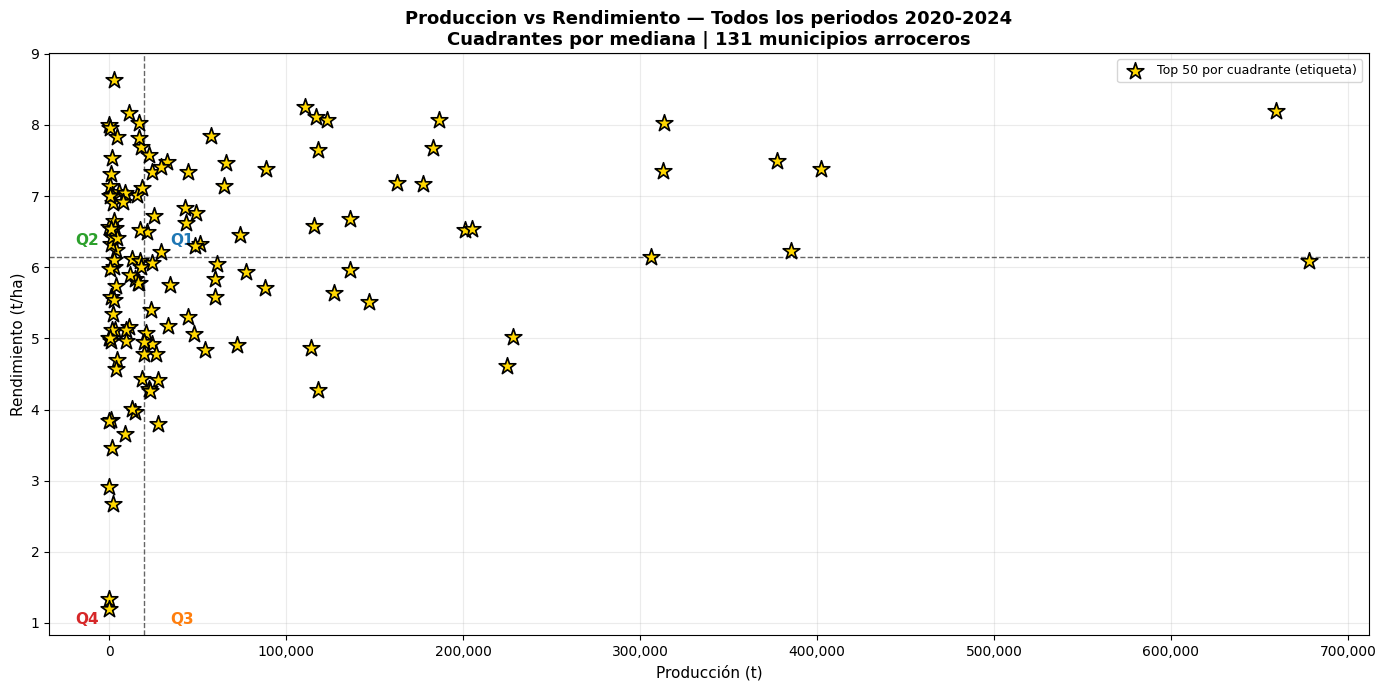

Total municipios en el grafico: 131
  Etiquetados Top50           : 131
  Sin etiqueta (igual validos) : 0


In [11]:
# ============================================================
# CELDA 11 [v2.0] — Scatter Produccion vs Rendimiento
# Correccion: usa Es_Top50 (no Es_Top50) y col_prod/col_rend
# detectados dinamicamente en CELDA 9.
# ============================================================

COLORES_Q = {
    'Q1 - Alto Rend + Alta Prod': '#1f77b4',
    'Q2 - Alto Rend + Baja Prod': '#2ca02c',
    'Q3 - Bajo Rend + Alta Prod': '#ff7f0e',
    'Q4 - Bajo Rend + Baja Prod': '#d62728'
}

fig, ax = plt.subplots(figsize=(14, 7))

# Municipios NO etiquetados como Top50 (fondo)
for q, df_q in df_mun[~df_mun['Es_Top50']].groupby('Cuadrante'):
    ax.scatter(
        df_q[col_prod],
        df_q[col_rend],
        s=40, alpha=0.55,
        c=COLORES_Q.get(q, '#7f7f7f'),
        label=q
    )

# Municipios etiquetados Top50 (estrellas doradas)
df_top = df_mun[df_mun['Es_Top50']].copy()
ax.scatter(
    df_top[col_prod],
    df_top[col_rend],
    s=160, c='#FFD700',
    edgecolors='black', linewidths=1.2,
    marker='*',
    label='Top 50 por cuadrante (etiqueta)',
    zorder=5
)

# Lineas de mediana
ax.axvline(prod_mediana, color='black', linestyle='--', linewidth=1, alpha=0.6)
ax.axhline(rend_mediana, color='black', linestyle='--', linewidth=1, alpha=0.6)

# Etiquetas de cuadrantes
xlim = ax.get_xlim()
ylim = ax.get_ylim()
ox = (xlim[1] - xlim[0]) * 0.02
oy = (ylim[1] - ylim[0]) * 0.02
ax.text(prod_mediana + ox, rend_mediana + oy, 'Q1', fontsize=11, color='#1f77b4', fontweight='bold')
ax.text(xlim[0]       + ox, rend_mediana + oy, 'Q2', fontsize=11, color='#2ca02c', fontweight='bold')
ax.text(prod_mediana + ox, ylim[0]       + oy, 'Q3', fontsize=11, color='#ff7f0e', fontweight='bold')
ax.text(xlim[0]       + ox, ylim[0]       + oy, 'Q4', fontsize=11, color='#d62728', fontweight='bold')

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_title(
    f'Produccion vs Rendimiento — Todos los periodos 2020-2024\n'
    f'Cuadrantes por mediana | {len(df_mun)} municipios arroceros',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel(str(col_prod), fontsize=11)
ax.set_ylabel(str(col_rend), fontsize=11)
ax.grid(True, alpha=0.25)
ax.legend(loc='best', fontsize=9)
plt.tight_layout()
plt.show()

print(f'Total municipios en el grafico: {len(df_mun)}')
print(f'  Etiquetados Top50           : {df_mun["Es_Top50"].sum()}')
print(f'  Sin etiqueta (igual validos) : {(~df_mun["Es_Top50"]).sum()}')


---
## 📈 CELDA 12 — Visualización: Evolución del rendimiento por departamento (serie 2020-2024)

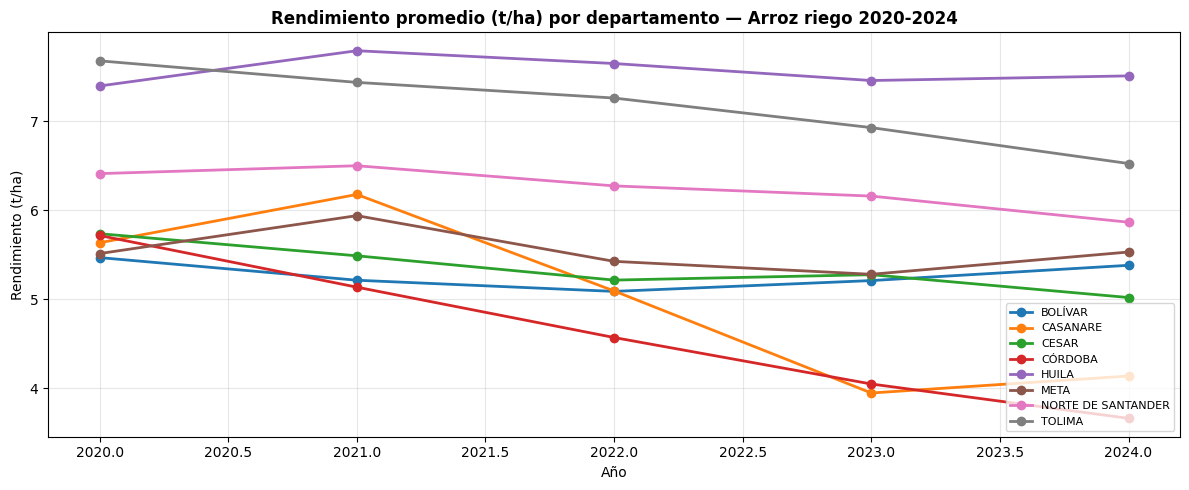

In [12]:
# ============================================================
# VISUALIZACIÓN — Rendimiento promedio por departamento y año
# ============================================================

# Top 8 departamentos por volumen de producción total
top_deptos = (
    df_agricola_EVA
    .groupby("Departamento")["Producción (t)"]
    .sum()
    .nlargest(8)
    .index.tolist()
)

df_evo = (
    df_agricola_EVA[
        df_agricola_EVA["Departamento"].isin(top_deptos)
    ]
    .groupby(["Departamento", "Año"])["Rendimiento (t/ha)"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

for depto, grupo in df_evo.groupby("Departamento"):
    ax.plot(
        grupo["Año"], grupo["Rendimiento (t/ha)"],
        marker="o", linewidth=2, label=depto
    )

ax.set_title("Rendimiento promedio (t/ha) por departamento — Arroz riego 2020-2024",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Año", fontsize=10)
ax.set_ylabel("Rendimiento (t/ha)", fontsize=10)
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 💾 CELDA 13 — Guardar dataset de municipios prioritarios en `data/processed/`

In [13]:
# ============================================================
# CELDA 13 [v2.0] — Guardar universo completo de municipios
# Hoja 1: Todos_municipios     -> UNIVERSO COMPLETO
# Hoja 2: Top50_por_cuadrante  -> etiquetados (compatibilidad MOD-02)
# Hoja 3: Resumen_departamento -> agregado por departamento
# ============================================================

df_hoja3 = (
    df_mun.groupby('Departamento', as_index=False)
    .agg(
        N_municipios         = ('Municipio',  'count'),
        Produccion_total_t   = (col_prod,     'sum'),
        Rendimiento_prom_tha = (col_rend,     'mean'),
        N_municipios_top50   = ('Es_Top50',   'sum'),
    )
    .sort_values('Produccion_total_t', ascending=False)
    .reset_index(drop=True)
)
df_hoja3['Rendimiento_prom_tha'] = df_hoja3['Rendimiento_prom_tha'].round(2)

with pd.ExcelWriter(ARCHIVO_MUNICIPIOS, engine='openpyxl') as writer:
    df_mun.to_excel(writer,          sheet_name='Todos_municipios',     index=False)
    tabla_top200.reset_index(drop=True).to_excel(
                             writer, sheet_name='Top50_por_cuadrante',  index=False)
    df_hoja3.to_excel(writer,        sheet_name='Resumen_departamento', index=False)

print(f'OK Guardado: 12_DF_Municipios_Prioritarios.xlsx')
print(f'   Ruta  : {ARCHIVO_MUNICIPIOS}')
print(f'   Hoja 1 Todos_municipios     : {len(df_mun):,} municipios (UNIVERSO COMPLETO)')
print(f'   Hoja 2 Top50_por_cuadrante  : {len(tabla_top200):,} municipios (etiquetados)')
print(f'   Hoja 3 Resumen_departamento : {len(df_hoja3):,} departamentos')


OK Guardado: 12_DF_Municipios_Prioritarios.xlsx
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/12_DF_Municipios_Prioritarios.xlsx
   Hoja 1 Todos_municipios     : 131 municipios (UNIVERSO COMPLETO)
   Hoja 2 Top50_por_cuadrante  : 131 municipios (etiquetados)
   Hoja 3 Resumen_departamento : 18 departamentos


---
## ✅ CELDA 14 — Resumen de ejecución del módulo

In [14]:
# ============================================================
# CELDA 14 [v2.0] — Resumen de ejecucion del modulo
# ============================================================

print('=' * 62)
print('  MOD-01 v2.0 — Ingesta Agricola EVA-UPRA COMPLETADO')
print('=' * 62)

print('\nArchivos generados:')
archivos = [
    ('data/raw/',       '01_raw_EVA_UPRA.xlsx',
     'Descarga original sin modificar'),
    ('data/processed/', '11_DF_Produccion_Agricola.xlsx',
     'Arroz riego 2020-2024 normalizado'),
    ('data/processed/', '12_DF_Municipios_Prioritarios.xlsx',
     'Universo completo + Top50 (etiqueta) + Resumen depto'),
]
for carpeta, archivo, desc in archivos:
    print(f'   {carpeta}{archivo}')
    print(f'      {desc}')

print('\nDataFrames disponibles para modulos siguientes:')
print(f'   df_agricola_EVA  -> {df_agricola_EVA.shape[0]:,} filas x {df_agricola_EVA.shape[1]} cols')
print(f'   df_mun           -> {len(df_mun):,} municipios (UNIVERSO COMPLETO arroz riego 2020-2024)')
print(f'   tabla_top200     -> {len(tabla_top200)} municipios etiquetados (referencia analitica)')
print(f'   con_estacion     -> {len(con_estacion)} pares depto-municipio para MOD-02')

print('\nTop 10 departamentos por N municipios:')
display(
    df_mun.groupby('Departamento')['Municipio']
    .count()
    .nlargest(10)
    .reset_index(name='N_municipios')
)

print(f'\n[v2.0] Cambio clave respecto a v1.0:')
print(f'   v1.0: ~97 municipios  (Top-50 por cuadrante del ultimo periodo)')
print(f'   v2.0: {len(df_mun)} municipios (todos con arroz riego 2020-2024)')

print('\nSiguiente modulo: MOD-02 — Estaciones Climaticas IDEAM')
print(f'   Entrada clave: con_estacion ({len(con_estacion)} pares depto-municipio)')
print('   NOTA: MOD-02 debe leer la hoja Todos_municipios, no Top50_por_cuadrante')
print('=' * 62)


  MOD-01 v2.0 — Ingesta Agricola EVA-UPRA COMPLETADO

Archivos generados:
   data/raw/01_raw_EVA_UPRA.xlsx
      Descarga original sin modificar
   data/processed/11_DF_Produccion_Agricola.xlsx
      Arroz riego 2020-2024 normalizado
   data/processed/12_DF_Municipios_Prioritarios.xlsx
      Universo completo + Top50 (etiqueta) + Resumen depto

DataFrames disponibles para modulos siguientes:
   df_agricola_EVA  -> 1,162 filas x 17 cols
   df_mun           -> 131 municipios (UNIVERSO COMPLETO arroz riego 2020-2024)
   tabla_top200     -> 131 municipios etiquetados (referencia analitica)
   con_estacion     -> 131 pares depto-municipio para MOD-02

Top 10 departamentos por N municipios:


,Departamento,N_municipios
0,TOLIMA,23
1,CESAR,18
2,HUILA,18
3,META,10
4,CASANARE,9
5,NORTE DE SANTANDER,9
6,BOLÍVAR,8
7,CAUCA,6
8,CÓRDOBA,6
9,MAGDALENA,6



[v2.0] Cambio clave respecto a v1.0:
   v1.0: ~97 municipios  (Top-50 por cuadrante del ultimo periodo)
   v2.0: 131 municipios (todos con arroz riego 2020-2024)

Siguiente modulo: MOD-02 — Estaciones Climaticas IDEAM
   Entrada clave: con_estacion (131 pares depto-municipio)
   NOTA: MOD-02 debe leer la hoja Todos_municipios, no Top50_por_cuadrante
